In [1]:
# Setup: run this cell first in every session
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("data/clean_public_procurement.parquet")
TARGET = "award_value_euro"
os.makedirs("reports/figures", exist_ok=True)
print(df.shape)

(365203, 22)


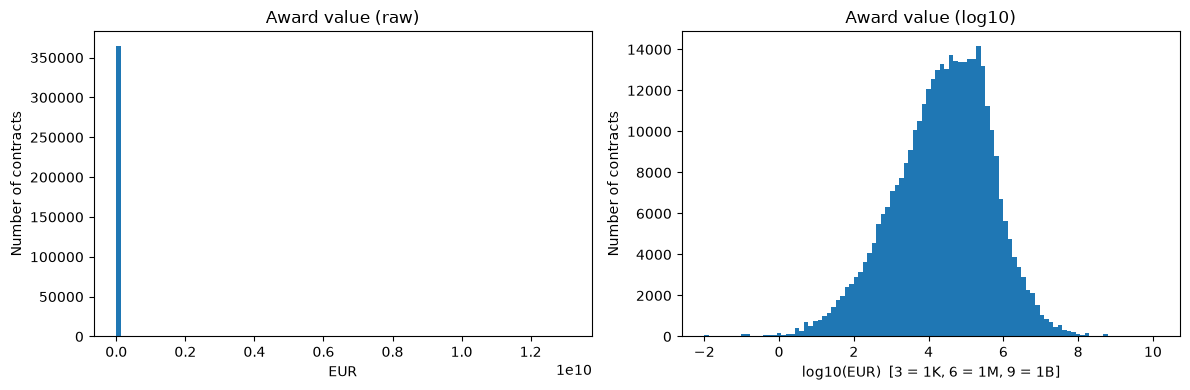

count    3.652030e+05
mean     1.315140e+06
std      4.645746e+07
min      1.000000e-02
25%      3.578220e+03
50%      3.074995e+04
75%      2.026568e+05
max      1.312147e+10
Name: award_value_euro, dtype: float64


In [2]:
# Target distribution: raw vs. log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df[TARGET], bins=100)
axes[0].set_title("Award value (raw)")
axes[0].set_xlabel("EUR")

axes[1].hist(np.log10(df[TARGET]), bins=100)
axes[1].set_title("Award value (log10)")
axes[1].set_xlabel("log10(EUR)  [3 = 1K, 6 = 1M, 9 = 1B]")

for ax in axes:
    ax.set_ylabel("Number of contracts")

plt.tight_layout()
plt.savefig("reports/figures/01_target_distribution.png", dpi=150)
plt.show()

print(df[TARGET].describe())

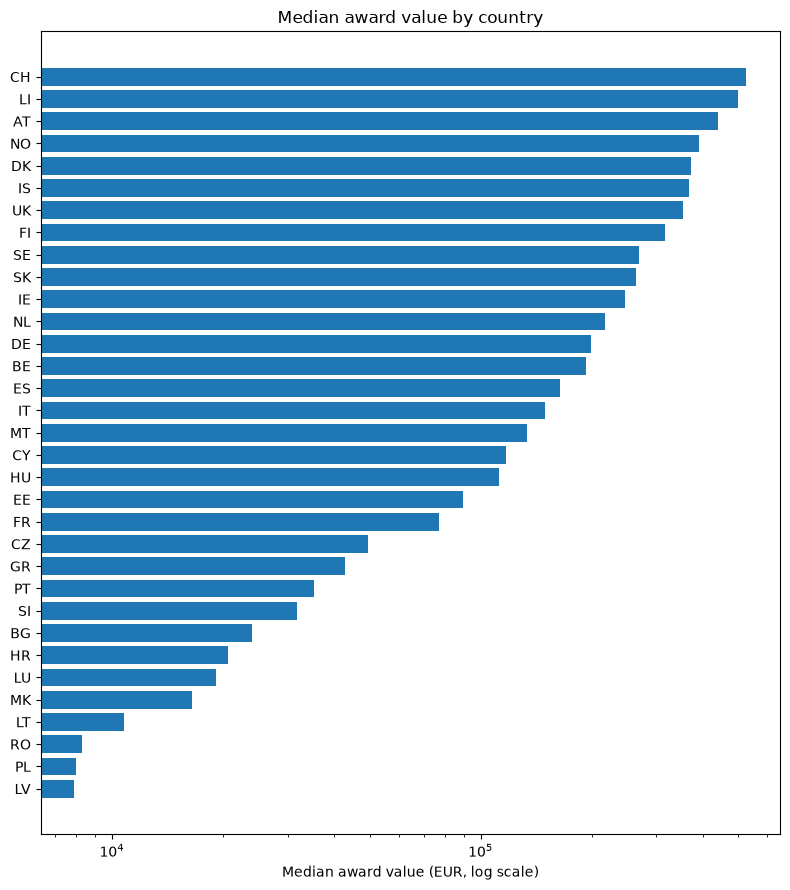

                      median   count
iso_country_code                    
PL                  7973.040  125583
FR                 77207.685   48486
RO                  8314.210   33560
IT                149159.925   17968
ES                164118.840   16581
DE                199726.975   16146
LV                  7904.000   15800
CZ                 49516.680   13312
BG                 23908.580    9108
HR                 20677.780    9031


In [3]:
# Median award value by country (with number of contracts)
country = df.groupby("iso_country_code")[TARGET].agg(["median", "count"]).sort_values("median")

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(country.index, country["median"])
ax.set_xscale("log")
ax.set_xlabel("Median award value (EUR, log scale)")
ax.set_title("Median award value by country")
plt.tight_layout()
plt.savefig("reports/figures/02_median_by_country.png", dpi=150)
plt.show()

print(country.sort_values("count", ascending=False).head(10))

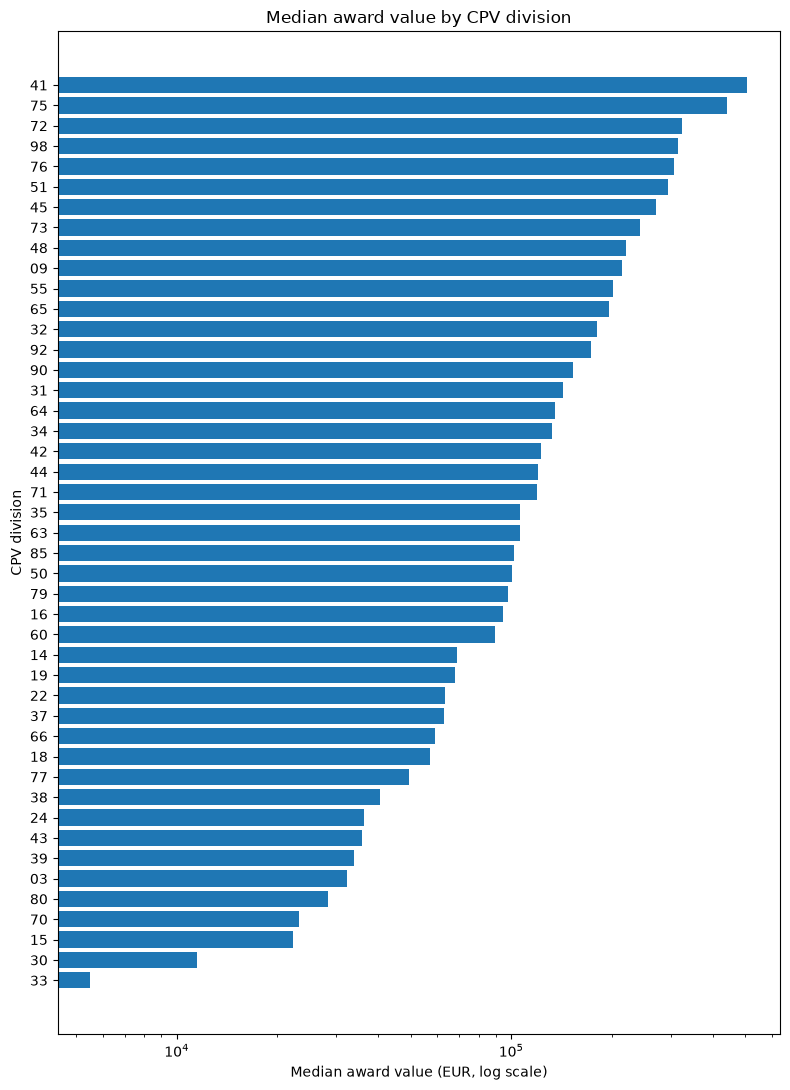

Number of divisions: 45
             median   count
cpv_div                    
33         5519.230  154779
45       271266.050   30150
90       152902.660   13123
71       119011.005   11710
15        22260.915   11520
50       100654.040   10964
34       132488.110   10735
77        49315.650   10136
30        11460.050    9700
79        97880.100    9038


In [4]:
# Median award value by CPV division (sector)
cpv = df.groupby("cpv_div")[TARGET].agg(["median", "count"]).sort_values("median")

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(cpv.index, cpv["median"])
ax.set_xscale("log")
ax.set_xlabel("Median award value (EUR, log scale)")
ax.set_ylabel("CPV division")
ax.set_title("Median award value by CPV division")
plt.tight_layout()
plt.savefig("reports/figures/03_median_by_cpv.png", dpi=150)
plt.show()

print("Number of divisions:", len(cpv))
print(cpv.sort_values("count", ascending=False).head(10))

In [5]:
# Hypothesis: are Polish medical (CPV 33) contracts a large share of the data?
is_pl = df["iso_country_code"] == "PL"
is_33 = df["cpv_div"] == "33"

print("Share of all rows that are PL & CPV 33:", round((is_pl & is_33).mean() * 100, 1), "%")
print("Share of CPV 33 rows that are from PL:", round(is_pl[is_33].mean() * 100, 1), "%")
print("Median value of PL & CPV 33:", df.loc[is_pl & is_33, TARGET].median())

# Lots per notice: do medical tenders have more lots (rows) per notice?
ids = pd.read_parquet("data/group_ids.parquet")["id_notice_can"]
rows_per_notice = ids.map(ids.value_counts())
print("\nMedian rows per notice, CPV 33:", rows_per_notice[is_33].median())
print("Median rows per notice, other sectors:", rows_per_notice[~is_33].median())

Share of all rows that are PL & CPV 33: 22.1 %
Share of CPV 33 rows that are from PL: 52.2 %
Median value of PL & CPV 33: 3897.9049999999997

Median rows per notice, CPV 33: 46.0
Median rows per notice, other sectors: 4.0


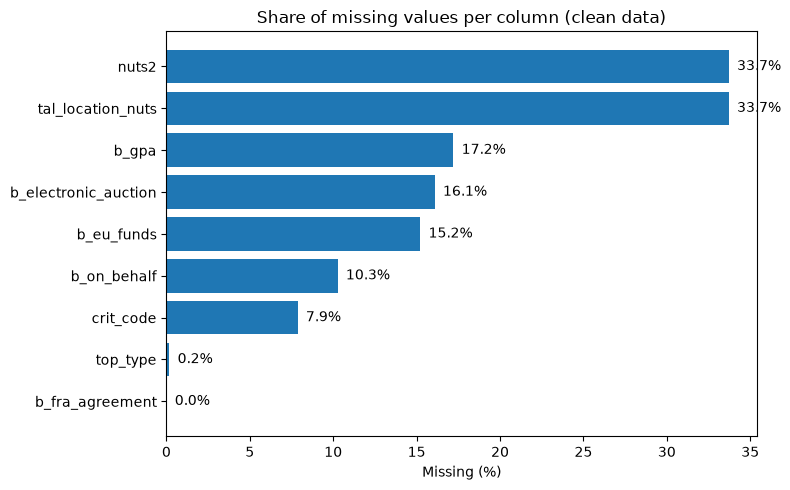

Rows with no missing values: 47.9 %


In [6]:
# Missing values per column (clean data)
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(missing.index, missing.values)
ax.invert_yaxis()
ax.set_xlabel("Missing (%)")
ax.set_title("Share of missing values per column (clean data)")
for i, v in enumerate(missing.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig("reports/figures/04_missing_values.png", dpi=150)
plt.show()

print("Rows with no missing values:", round(df.notna().all(axis=1).mean() * 100, 1), "%")

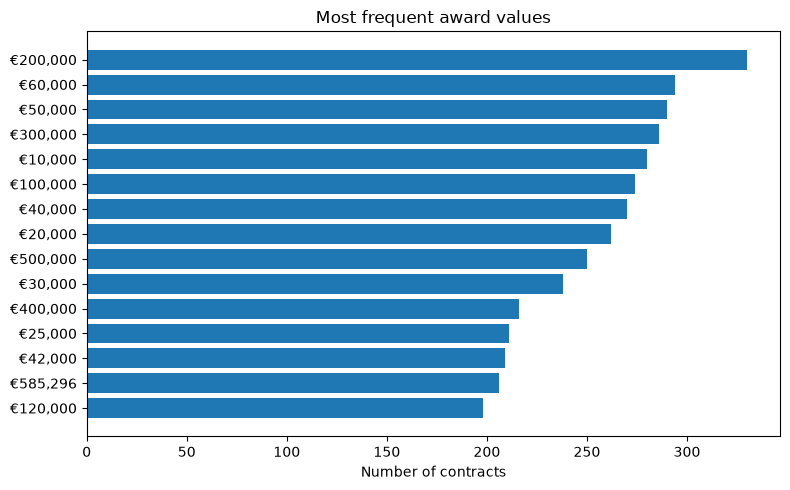

Multiples of €1,000: 5.2%
Multiples of €10,000: 2.7%
Multiples of €100,000: 1.1%


In [7]:
# Rounded values: most frequent award values
top = df[TARGET].value_counts().head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"€{v:,.0f}" for v in top.index], top.values)
ax.invert_yaxis()
ax.set_xlabel("Number of contracts")
ax.set_title("Most frequent award values")
plt.tight_layout()
plt.savefig("reports/figures/05_frequent_values.png", dpi=150)
plt.show()

for step in [1_000, 10_000, 100_000]:
    share = (df[TARGET] % step == 0).mean() * 100
    print(f"Multiples of €{step:,}: {share:.1f}%")

In [8]:
# Check the repeated non-round value (~€585,296)
odd = df[df[TARGET].between(585295, 585297)]
print("Rows:", len(odd))
print("Countries:", odd["iso_country_code"].value_counts().to_dict())
print("CPV divisions:", odd["cpv_div"].value_counts().head(3).to_dict())
print("Distinct notices:", ids[odd.index].nunique())

Rows: 206
Countries: {'PL': 206}
CPV divisions: {'92': 206}
Distinct notices: 1


In [9]:
# How common is "same value copied to every lot of a notice"?
lots = pd.DataFrame({"notice": ids, "value": df[TARGET]})
per_notice = lots.groupby("notice")["value"].agg(["count", "nunique"])

multi = per_notice[per_notice["count"] > 1]
same = multi[multi["nunique"] == 1]

print("Notices with more than one row:", len(multi))
print("...where every row has the same value:", len(same), f"({len(same) / len(multi) * 100:.1f}%)")
print("Rows affected:", same["count"].sum(), f"({same['count'].sum() / len(df) * 100:.1f}% of all rows)")
print("\nLargest cases (rows per notice):")
print(same.sort_values("count", ascending=False).head(5))

Notices with more than one row: 30818
...where every row has the same value: 2081 (6.8%)
Rows affected: 8683 (2.4% of all rows)

Largest cases (rows per notice):
            count  nunique
notice                    
2015136775    123        1
201552616     111        1
2015426070    109        1
2015291218    104        1
2015374363     84        1


In [10]:
# Bring back title and authority name from the raw data (same filtering = same row order)
raw = pd.read_parquet("data/raw_public_procurement.parquet",
                      columns=["id_notice_can", TARGET, "title", "cae_name"])
raw = raw[raw[TARGET] > 0].reset_index(drop=True)
print("Aligned with clean data:", (raw["id_notice_can"].values == ids.values).all())

# 20 most expensive records
pd.set_option("display.max_colwidth", 50)
top = df.assign(title=raw["title"], authority=raw["cae_name"]).nlargest(20, TARGET)
print(top[[TARGET, "iso_country_code", "cpv_div", "lots_number", "title", "authority"]].to_string())

# Implausibly small values
for limit in [1, 10, 100]:
    print(f"Values below €{limit}:", (df[TARGET] < limit).sum())

Aligned with clean data: True
        award_value_euro iso_country_code cpv_div  lots_number                                                                                                                                                 title                                                             authority
98711       1.312147e+10               UK      85            0                                                                                                                                                   NaN                         NHS Vale of York Clinical Commissioning Group
345061      1.270834e+10               UK      85            0                                                                                                                                                   NaN               Birmingham City Council, Corporate Procurement Services
337415      1.081500e+10               FR      60            0                                                           

In [11]:
# Manual review of the 20 most expensive records
suspect_high = {
    98711: "Far above the budget of one local health body; likely a framework ceiling",
    345061: "Far above one council's budget; likely a framework ceiling",
    305708: "One row aggregates 1,763 drug lots (see title)",
    54702: "EUR 1.9B for renovating one street; likely HUF entered as EUR",
    153841: "EUR 1.3B for clothing; likely wrong currency or extra digits",
}
for i in range(292562, 292567):
    suspect_high[i] = "Same value copied to several lots of one notice"

review = top[[TARGET, "iso_country_code", "cpv_div", "title", "authority"]].copy()
review["verdict"] = np.where(review.index.isin(list(suspect_high)), "suspect", "plausible")
review["reason"] = review.index.map(suspect_high).fillna("Large infrastructure, transport or defence contract")
review.to_csv("reports/top20_review.csv")

# Data quality flags (same row order as the clean data). Not model features!
flags = pd.DataFrame({
    "is_repeated_value": ids.isin(same.index),
    "is_suspect_low": df[TARGET] < 100,
    "is_suspect_high": df.index.isin(list(suspect_high)),
})
flags.to_parquet("data/quality_flags.parquet", index=False)
print(flags.sum())

is_repeated_value     8683
is_suspect_low       17052
is_suspect_high         10
dtype: int64
